# Chapter 5: Support Vector Machines (SVM) — Practice Notebook

Support Vector Machines (SVM) are powerful, versatile models capable of performing linear or non-linear classification, regression, and outlier detection. They are especially suited for complex small-to-medium-sized datasets.

In [1]:
import sys
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import sklearn

# Reproducibility
np.random.seed(42)

# Plotting configuration
%matplotlib inline
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Helper function to save figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "svm"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)


## 1. Large Margin Classification (Figure 5-1)

SVM doesn't just find *any* boundary line separating classes; it fits the **widest possible street** between them. The boundary is fully supported by the border instances standing on the edge of the street (**Support Vectors**).

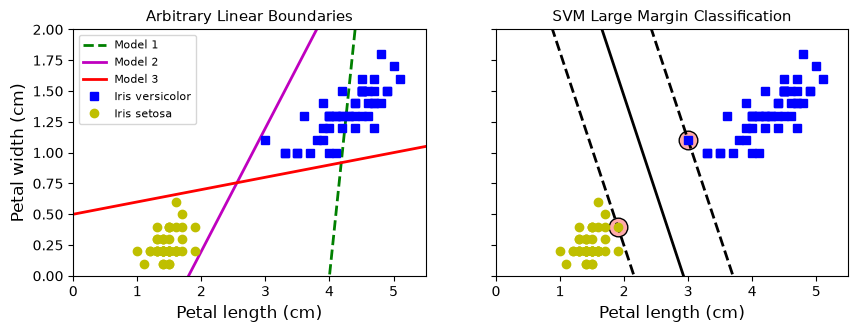

In [2]:
from sklearn.svm import SVC
from sklearn import datasets

# 1. Load Iris dataset (Petal length & Petal width) for Setosa and Versicolor
iris = datasets.load_iris()
X = iris["data"][:, (2, 3)]
y = iris["target"]

setosa_or_versicolor = (y == 0) | (y == 1)
X = X[setosa_or_versicolor]
y = y[setosa_or_versicolor]

# 2. Train Hard Margin Linear SVM (C=inf means zero margin violations allowed)
svm_clf = SVC(kernel="linear", C=float("inf"))
svm_clf.fit(X, y)

# 3. Bad linear models for comparison
x0 = np.linspace(0, 5.5, 200)
pred_1 = 5 * x0 - 20
pred_2 = x0 - 1.8
pred_3 = 0.1 * x0 + 0.5

def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]
    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0]/w[1] * x0 - b/w[1]
    margin = 1 / w[1]
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin
    svs = svm_clf.support_vectors_
    plt.scatter(svs[:, 0], svs[:, 1], s=180, facecolors='#FFAAAA', edgecolors='k', label="Support Vectors")
    plt.plot(x0, decision_boundary, "k-", linewidth=2, label="Decision Boundary")
    plt.plot(x0, gutter_up, "k--", linewidth=2, label="Margin (Street edge)")
    plt.plot(x0, gutter_down, "k--", linewidth=2)

fig, axes = plt.subplots(ncols=2, figsize=(10, 3.2), sharey=True)
plt.sca(axes[0])
plt.plot(x0, pred_1, "g--", linewidth=2)
plt.plot(x0, pred_2, "m-", linewidth=2)
plt.plot(x0, pred_3, "r-", linewidth=2)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris versicolor")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris setosa")
plt.xlabel("Petal length (cm)", fontsize=12)
plt.ylabel("Petal width (cm)", fontsize=12)
plt.legend(loc="upper left", fontsize=9)
plt.axis([0, 5.5, 0, 2])
plt.title("Arbitrary Linear Boundaries", fontsize=11)

plt.sca(axes[1])
plot_svc_decision_boundary(svm_clf, 0, 5.5)
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs")
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo")
plt.xlabel("Petal length (cm)", fontsize=12)
plt.axis([0, 5.5, 0, 2])
plt.title("SVM Large Margin Classification", fontsize=11)
save_fig("large_margin_classification_plot")
plt.show()


**What's going on in Figure 5-1:**
* **Left Plot (Other Linear Models)**: Model 1 misclassifies. Models 2 & 3 separate the training data but pass dangerously close to the points, leading to poor generalization on new data.
* **Right Plot (SVM)**: Solid line is the decision boundary; dashed lines are the margins (the street). Circled points are the **support vectors** holding up the street. Adding more points far away from the street has **zero effect** on the boundary.

## 2. Sensitivity to Feature Scales (Figure 5-2)

SVM tries to maximize the margin in all directions. If features have very different scales (e.g., $x_0 \in [1, 5]$ while $x_1 \in [20, 80]$), the street gets heavily squeezed horizontally.

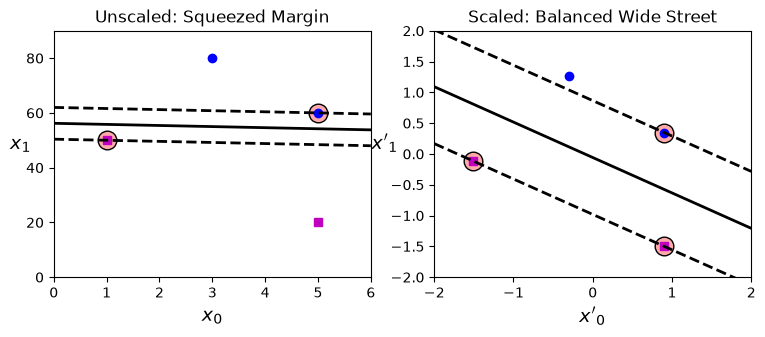

In [3]:
from sklearn.preprocessing import StandardScaler

# 1. Unscaled toy dataset
Xs = np.array([[1, 50], [5, 20], [3, 80], [5, 60]]).astype(np.float64)
ys = np.array([0, 0, 1, 1])

svm_clf_unscaled = SVC(kernel="linear", C=100)
svm_clf_unscaled.fit(Xs, ys)

plt.figure(figsize=(9, 3.2))
plt.subplot(121)
plt.plot(Xs[:, 0][ys==1], Xs[:, 1][ys==1], "bo")
plt.plot(Xs[:, 0][ys==0], Xs[:, 1][ys==0], "ms")
plot_svc_decision_boundary(svm_clf_unscaled, 0, 6)
plt.xlabel("$x_0$", fontsize=14)
plt.ylabel("$x_1$", fontsize=14, rotation=0)
plt.title("Unscaled: Squeezed Margin", fontsize=12)
plt.axis([0, 6, 0, 90])

# 2. Scaled with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(Xs)
svm_clf_scaled = SVC(kernel="linear", C=100)
svm_clf_scaled.fit(X_scaled, ys)

plt.subplot(122)
plt.plot(X_scaled[:, 0][ys==1], X_scaled[:, 1][ys==1], "bo")
plt.plot(X_scaled[:, 0][ys==0], X_scaled[:, 1][ys==0], "ms")
plot_svc_decision_boundary(svm_clf_scaled, -2, 2)
plt.xlabel("$x'_0$", fontsize=14)
plt.ylabel("$x'_1$", fontsize=14, rotation=0)
plt.title("Scaled: Balanced Wide Street", fontsize=12)
plt.axis([-2, 2, -2, 2])
save_fig("sensitivity_to_feature_scales_plot")
plt.show()


**What's going on in Figure 5-2:**
* **Unscaled (Left)**: The vertical feature ($x_1$) has a much larger range ($0$ to $90$) than $x_0$ ($0$ to $6$). This crushes the street into a nearly horizontal line with an ultra-thin margin on $x_0$.
* **Scaled (Right)**: After standard scaling, the decision boundary looks balanced with a wide, isotropic street. **Always scale your features when using SVMs!**

## 3. Hard Margin Sensitivity to Outliers (Figure 5-3)

Hard Margin classification strictly demands zero violations. This has two major problems:
1. It is **impossible** if data is not linearly separable.
2. A single outlier can wildly distort the boundary (overfitting).

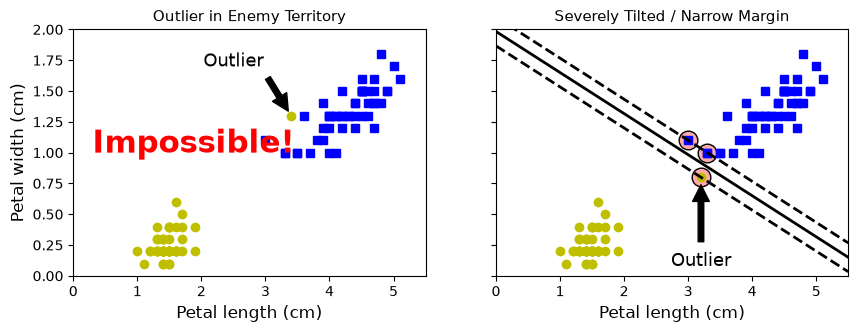

In [4]:
# 1. Create two scenarios with outliers
X_outliers = np.array([[3.4, 1.3], [3.2, 0.8]])
y_outliers = np.array([0, 0])
Xo1 = np.concatenate([X_bin, X_outliers[:1]], axis=0)
yo1 = np.concatenate([y_bin, y_outliers[:1]], axis=0)
Xo2 = np.concatenate([X_bin, X_outliers[1:]], axis=0)
yo2 = np.concatenate([y_bin, y_outliers[1:]], axis=0)

# 2. Fit model with second outlier (extreme high C = hard margin)
svm_clf2 = SVC(kernel="linear", C=10**9)
svm_clf2.fit(Xo2, yo2)

fig, axes = plt.subplots(ncols=2, figsize=(10, 3.2), sharey=True)
plt.sca(axes[0])
plt.plot(Xo1[:, 0][yo1==1], Xo1[:, 1][yo1==1], "bs")
plt.plot(Xo1[:, 0][yo1==0], Xo1[:, 1][yo1==0], "yo")
plt.text(0.3, 1.0, "Impossible!", fontsize=22, color="red", weight="bold")
plt.xlabel("Petal length (cm)", fontsize=12)
plt.ylabel("Petal width (cm)", fontsize=12)
plt.annotate("Outlier", xy=(X_outliers[0][0], X_outliers[0][1]), xytext=(2.5, 1.7),
             ha="center", arrowprops=dict(facecolor='black', shrink=0.1), fontsize=13)
plt.axis([0, 5.5, 0, 2])
plt.title("Outlier in Enemy Territory", fontsize=11)

plt.sca(axes[1])
plt.plot(Xo2[:, 0][yo2==1], Xo2[:, 1][yo2==1], "bs")
plt.plot(Xo2[:, 0][yo2==0], Xo2[:, 1][yo2==0], "yo")
plot_svc_decision_boundary(svm_clf2, 0, 5.5)
plt.xlabel("Petal length (cm)", fontsize=12)
plt.annotate("Outlier", xy=(X_outliers[1][0], X_outliers[1][1]), xytext=(3.2, 0.08),
             ha="center", arrowprops=dict(facecolor='black', shrink=0.1), fontsize=13)
plt.axis([0, 5.5, 0, 2])
plt.title("Severely Tilted / Narrow Margin", fontsize=11)
save_fig("sensitivity_to_outliers_plot")
plt.show()


**What's going on in Figure 5-3:**
* **Left Plot**: The outlier is on the other side of the cluster. No straight line can separate them without errors $\to$ Hard margin fails completely (*"Impossible!"*).
* **Right Plot**: The outlier forces the street to become narrow and heavily tilted compared to Figure 5-1. This is why we need **Soft Margin Classification**.

## 4. Production Linear SVM: `LinearSVC` with Pipeline

In practice, `LinearSVC` is faster than `SVC(kernel="linear")` for large linear datasets. Always bundle it with `StandardScaler` inside a `Pipeline`.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# 1. Load data (detect Iris virginica: 1 if virginica, else 0)
X_iris = iris["data"][:, (2, 3)]  # petal length, petal width
y_virginica = (iris["target"] == 2).astype(np.float64)

# 2. Build Pipeline: Scaler + LinearSVC
svm_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("linear_svc", LinearSVC(C=1, loss="hinge", random_state=42, max_iter=10000)),
])
svm_clf.fit(X_iris, y_virginica)

# 3. Predict on a new sample [petal length = 5.5 cm, petal width = 1.7 cm]
sample = [[5.5, 1.7]]
prediction = svm_clf.predict(sample)[0]
decision_score = svm_clf.decision_function(sample)[0]

print(f"Sample {sample}:")
print(f"-> Prediction: {'Iris virginica (class 1)' if prediction == 1 else 'Not Iris virginica (class 0)'}")
print(f"-> Decision Function Score: {decision_score:.3f} (Score > 0 predicts class 1)")


Sample [[5.5, 1.7]]:
-> Prediction: Iris virginica (class 1)
-> Decision Function Score: 0.686 (Score > 0 predicts class 1)


## 5. Soft Margin: Tuning the Street Width ($C=1$ vs $C=100$) (Figure 5-4)

The hyperparameter $C$ acts as our regularization control knob:
* **Low $C$** ($C=1$): Relaxed margin. Wider street, allows some margin violations $\to$ better generalization.
* **High $C$** ($C=100$): Strict margin. Narrower street, fewer margin violations $\to$ risks overfitting.

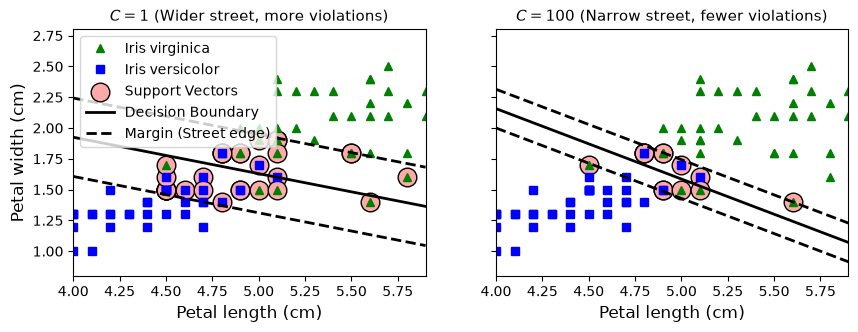

In [6]:
# 1. Train two models with different C values
scaler_f4 = StandardScaler()
svm_clf1 = LinearSVC(C=1, loss="hinge", random_state=42, max_iter=10000)
svm_clf2 = LinearSVC(C=100, loss="hinge", random_state=42, max_iter=10000)

scaled_svm_clf1 = Pipeline([("scaler", scaler_f4), ("linear_svc", svm_clf1)])
scaled_svm_clf2 = Pipeline([("scaler", scaler_f4), ("linear_svc", svm_clf2)])

scaled_svm_clf1.fit(X_iris, y_virginica)
scaled_svm_clf2.fit(X_iris, y_virginica)

# 2. Convert to unscaled parameters to plot on the original data scale
b1 = svm_clf1.decision_function([-scaler_f4.mean_ / scaler_f4.scale_])
b2 = svm_clf2.decision_function([-scaler_f4.mean_ / scaler_f4.scale_])
w1 = svm_clf1.coef_[0] / scaler_f4.scale_
w2 = svm_clf2.coef_[0] / scaler_f4.scale_
svm_clf1.intercept_ = np.array([b1])
svm_clf2.intercept_ = np.array([b2])
svm_clf1.coef_ = np.array([w1])
svm_clf2.coef_ = np.array([w2])

# 3. Find support vectors (LinearSVC does not track them automatically)
t = y_virginica * 2 - 1
support_vectors_idx1 = (t * (X_iris.dot(w1) + b1) < 1).ravel()
support_vectors_idx2 = (t * (X_iris.dot(w2) + b2) < 1).ravel()
svm_clf1.support_vectors_ = X_iris[support_vectors_idx1]
svm_clf2.support_vectors_ = X_iris[support_vectors_idx2]

# 4. Plot both side by side
fig, axes = plt.subplots(ncols=2, figsize=(10, 3.2), sharey=True)
plt.sca(axes[0])
plt.plot(X_iris[:, 0][y_virginica==1], X_iris[:, 1][y_virginica==1], "g^", label="Iris virginica")
plt.plot(X_iris[:, 0][y_virginica==0], X_iris[:, 1][y_virginica==0], "bs", label="Iris versicolor")
plot_svc_decision_boundary(svm_clf1, 4, 5.9)
plt.xlabel("Petal length (cm)", fontsize=12)
plt.ylabel("Petal width (cm)", fontsize=12)
plt.legend(loc="upper left", fontsize=10)
plt.title(r"$C = 1$ (Wider street, more violations)", fontsize=11)
plt.axis([4, 5.9, 0.8, 2.8])

plt.sca(axes[1])
plt.plot(X_iris[:, 0][y_virginica==1], X_iris[:, 1][y_virginica==1], "g^")
plt.plot(X_iris[:, 0][y_virginica==0], X_iris[:, 1][y_virginica==0], "bs")
plot_svc_decision_boundary(svm_clf2, 4, 5.99)
plt.xlabel("Petal length (cm)", fontsize=12)
plt.title(r"$C = 100$ (Narrow street, fewer violations)", fontsize=11)
plt.axis([4, 5.9, 0.8, 2.8])
save_fig("regularization_plot")
plt.show()


**What's going on in Figure 5-4:**
* **Left Plot ($C=1$)**: The street is wider and allows some instances inside the street (margin violations). Most points stay on their correct side, and the model generalizes much better.
* **Right Plot ($C=100$)**: The street is narrow and strict, avoiding margin violations as much as possible. If an SVM model is overfitting, you can regularize it by **reducing $C$**.

## 6. Non-linear SVM: Adding Polynomial Features (Figure 5-6)

Many real-world datasets are not linearly separable (like the **moons dataset**).

One straightforward way to handle non-linear data is adding **polynomial features** (via `PolynomialFeatures`). By projecting the data into a higher-dimensional feature space, a standard `LinearSVC` can find a linear boundary there, which translates to a **curved non-linear boundary** in the original 2D space.

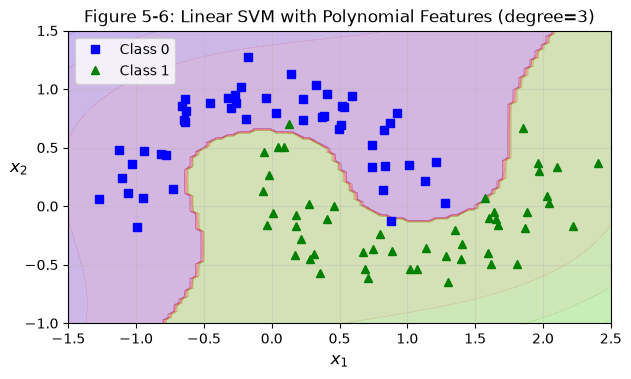

In [7]:
from sklearn.datasets import make_moons
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.svm import LinearSVC

# 1. Generate non-linear toy data (two interleaving half circles)
X, y = make_moons(n_samples=100, noise=0.15, random_state=42)

# 2. Build Pipeline: Polynomial Features (degree=3) + Scaler + LinearSVC
polynomial_svm_clf = Pipeline([
    ("poly_features", PolynomialFeatures(degree=3)),
    ("scaler", StandardScaler()),
    ("svm_clf", LinearSVC(C=10, loss="hinge", random_state=42, max_iter=10000))
])
polynomial_svm_clf.fit(X, y)

# 3. Plot the non-linear decision boundary
def plot_dataset(X, y, axes):
    plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], "bs", label="Class 0")
    plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], "g^", label="Class 1")
    plt.axis(axes)
    plt.grid(True, alpha=0.3)
    plt.xlabel("$x_1$", fontsize=12)
    plt.ylabel("$x_2$", fontsize=12, rotation=0)

def plot_predictions(clf, axes):
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s)
    X_grid = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X_grid).reshape(x0.shape)
    y_decision = clf.decision_function(X_grid).reshape(x0.shape)
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)
    plt.contourf(x0, x1, y_decision, cmap=plt.cm.brg, alpha=0.1)

plt.figure(figsize=(7, 3.8))
plot_predictions(polynomial_svm_clf, [-1.5, 2.5, -1, 1.5])
plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])
plt.title("Figure 5-6: Linear SVM with Polynomial Features (degree=3)", fontsize=12)
plt.legend(loc="upper left", fontsize=10)
save_fig("linear_svm_polynomial_features_plot")
plt.show()


**What's going on in Figure 5-6:**
* **Curved Decision Boundary**: Even though `LinearSVC` is strictly a linear model, feeding it 3rd-degree polynomial combinations ($x_1^2, x_2^2, x_1 x_2, x_1^3, \dots$) allows it to wrap around and cleanly separate the two interlocking moons.
* **The Polynomial Limitation**: 
  - **Low degree**: Cannot handle complex curves.
  - **High degree**: Generates a massive combinatorial explosion of features, making training extremely slow and prone to overfitting.

## 7. Similarity Features using the Gaussian RBF (Figure 5-8)

Instead of adding polynomial combinations, another way to separate non-linear data is by computing **similarity features** with a bell-shaped **Gaussian Radial Basis Function (RBF)**:

$$\phi_\gamma(\mathbf{x}, \boldsymbol{\ell}) = \exp(-\gamma \|\mathbf{x} - \boldsymbol{\ell}\|^2)$$

By measuring the closeness of each point to specific **landmarks** (e.g., at $\ell_1 = -2$ and $\ell_2 = 1$), 1D non-linear points get transformed into a 2D space where they become **linearly separable**.

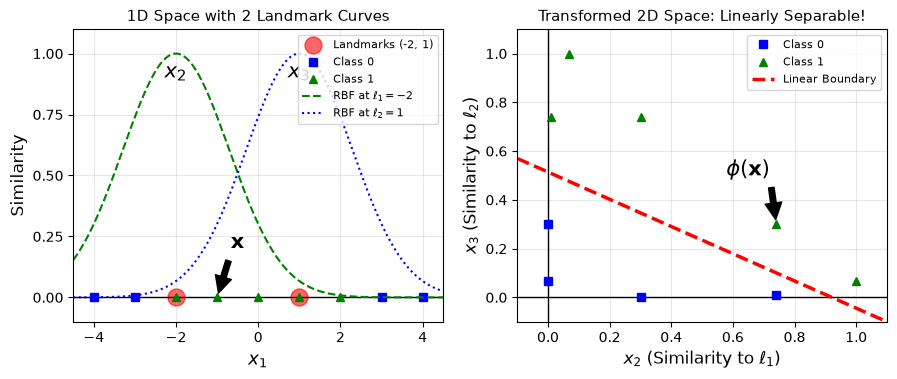

Example point x = -1.0:
-> Similarity to landmark -2: phi(x, -2) = 0.7408
-> Similarity to landmark  1: phi(x,  1) = 0.3012


In [8]:
# 1. Define Gaussian RBF similarity function
def gaussian_rbf(x, landmark, gamma):
    return np.exp(-gamma * np.linalg.norm(x - landmark, axis=1)**2)

gamma = 0.3

# 2. 1D dataset and 2 landmark points (-2 and 1)
X1D = np.linspace(-4, 4, 9).reshape(-1, 1)
x1s = np.linspace(-4.5, 4.5, 200).reshape(-1, 1)
x2s = gaussian_rbf(x1s, -2, gamma)
x3s = gaussian_rbf(x1s, 1, gamma)

XK = np.c_[gaussian_rbf(X1D, -2, gamma), gaussian_rbf(X1D, 1, gamma)]
yk = np.array([0, 0, 1, 1, 1, 1, 1, 0, 0])

# 3. Plot 1D space with bell curves vs Transformed 2D space
plt.figure(figsize=(10.5, 3.8))

plt.subplot(121)
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linewidth=1)
plt.scatter(x=[-2, 1], y=[0, 0], s=150, alpha=0.6, c="red", label="Landmarks (-2, 1)")
plt.plot(X1D[:, 0][yk==0], np.zeros(4), "bs", label="Class 0")
plt.plot(X1D[:, 0][yk==1], np.zeros(5), "g^", label="Class 1")
plt.plot(x1s, x2s, "g--", label=r"RBF at $\ell_1 = -2$")
plt.plot(x1s, x3s, "b:", label=r"RBF at $\ell_2 = 1$")
plt.gca().get_yaxis().set_ticks([0, 0.25, 0.5, 0.75, 1])
plt.xlabel(r"$x_1$", fontsize=13)
plt.ylabel(r"Similarity", fontsize=12)
plt.annotate(r'$\mathbf{x}$', xy=(X1D[3, 0], 0), xytext=(-0.5, 0.20),
             ha="center", arrowprops=dict(facecolor='black', shrink=0.1), fontsize=15)
plt.text(-2, 0.9, "$x_2$", ha="center", fontsize=15)
plt.text(1, 0.9, "$x_3$", ha="center", fontsize=15)
plt.legend(loc="upper right", fontsize=8)
plt.axis([-4.5, 4.5, -0.1, 1.1])
plt.title("1D Space with 2 Landmark Curves", fontsize=11)

plt.subplot(122)
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linewidth=1)
plt.axvline(x=0, color='k', linewidth=1)
plt.plot(XK[:, 0][yk==0], XK[:, 1][yk==0], "bs", label="Class 0")
plt.plot(XK[:, 0][yk==1], XK[:, 1][yk==1], "g^", label="Class 1")
plt.xlabel(r"$x_2$ (Similarity to $\ell_1$)", fontsize=12)
plt.ylabel(r"$x_3$ (Similarity to $\ell_2$)", fontsize=12)
plt.annotate(r'$\phi\left(\mathbf{x}\right)$', xy=(XK[3, 0], XK[3, 1]), xytext=(0.65, 0.50),
             ha="center", arrowprops=dict(facecolor='black', shrink=0.1), fontsize=15)
plt.plot([-0.1, 1.1], [0.57, -0.1], "r--", linewidth=2.5, label="Linear Boundary")
plt.legend(loc="upper right", fontsize=8)
plt.axis([-0.1, 1.1, -0.1, 1.1])
plt.title("Transformed 2D Space: Linearly Separable!", fontsize=11)

save_fig("kernel_method_plot")
plt.show()

# 4. Closeness score for sample point x = -1
x1_example = X1D[3, 0]
for landmark in (-2, 1):
    k = gaussian_rbf(np.array([[x1_example]]), np.array([[landmark]]), gamma)
    print(f"Phi({x1_example}, {landmark}) = {k[0]:.4f}")


**What's going on in Figure 5-8:**
* **Left Plot (1D Space)**: The green triangles in the middle cannot be separated from the blue squares on the edges with a single straight line.
* **Right Plot (Transformed 2D Space)**: Each point's new coordinates $(x_2, x_3)$ are its similarity scores to landmark $-2$ and landmark $1$. In this new 2D space, the green triangles cluster together at the top-right and are **cleanly separated by a straight dashed red line**!

## 8. Gaussian RBF Kernel (Figure 5-9)

Instead of computing an $m \times m$ matrix of similarity features in memory, `SVC(kernel="rbf")` uses the **Kernel Trick** to obtain the exact same result mathematically on-the-fly.

- **$\gamma$ (Gamma)**: Controls the bell curve reach. High $\gamma$ = narrow reach (wiggly boundary / overfitting); Low $\gamma$ = wide reach (smooth boundary / underfitting).
- **$C$**: Controls margin strictness. High $C$ = narrow street; Low $C$ = wide street.

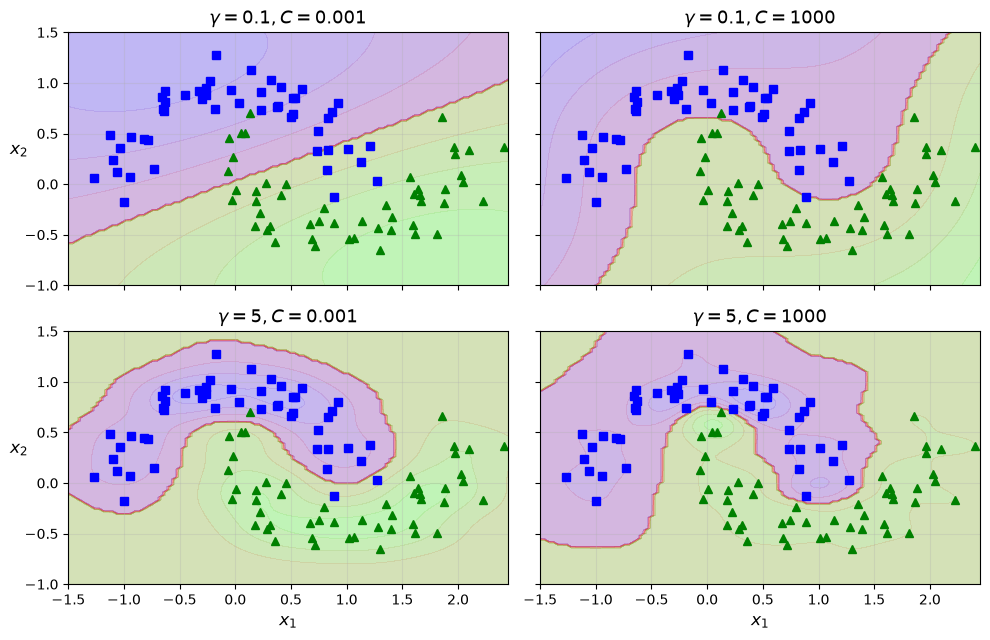

In [9]:
from sklearn.svm import SVC

# 1. Define hyperparameter grid: 2 values of gamma x 2 values of C
gamma1, gamma2 = 0.1, 5
C1, C2 = 0.001, 1000
hyperparams = [(gamma1, C1), (gamma1, C2), (gamma2, C1), (gamma2, C2)]

svm_clfs = []
for gamma_val, c_val in hyperparams:
    rbf_kernel_svm_clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svm_clf", SVC(kernel="rbf", gamma=gamma_val, C=c_val))
    ])
    rbf_kernel_svm_clf.fit(X, y)
    svm_clfs.append(rbf_kernel_svm_clf)

# 2. Plot 2x2 comparison grid
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 6.5), sharex=True, sharey=True)

for i, svm_clf in enumerate(svm_clfs):
    plt.sca(axes[i // 2, i % 2])
    plot_predictions(svm_clf, [-1.5, 2.45, -1, 1.5])
    plot_dataset(X, y, [-1.5, 2.45, -1, 1.5])
    gamma_val, c_val = hyperparams[i]
    plt.title(rf"$\gamma = {gamma_val}, C = {c_val}$", fontsize=13)
    if i in (0, 1):
        plt.xlabel("")
    if i in (1, 3):
        plt.ylabel("")

plt.tight_layout()
save_fig("moons_rbf_svc_plot")
plt.show()


**What's going on in Figure 5-9:**
* **Top-Left ($\gamma=0.1, C=0.001$)**: Low $\gamma$ (broad reach) + low $C$ (wide margin) $\to$ extremely smooth, almost flat boundary (**Underfitting**).
* **Top-Right ($\gamma=0.1, C=1000$)**: Low $\gamma$ (smooth) + high $C$ (strict) $	o$ smooth, well-shaped curve following the moons.
* **Bottom-Left ($\gamma=5, C=0.001$)**: High $\gamma$ (local reach) + low $C$ $	o$ soft islands around points.
* **Bottom-Right ($\gamma=5, C=1000$)**: High $\gamma$ + high $C$ $	o$ extremely irregular, wiggly boundary wrapping tightly around individual points (**Overfitting**).
* *Regularization Rule*: If your model is **overfitting**, reduce $\gamma$ and/or reduce $C$.

## 9. SVM Regression: Linear (Figure 5-10)

SVM Regression **reverses the objective** of SVM Classification:
* **Classification**: Tries to fit the widest possible street between two classes while keeping points *off* the street.
* **Regression**: Tries to fit **as many instances as possible inside the street**, while limiting violations (points off the street).

> The street width is controlled by hyperparameter $\epsilon$ (epsilon). Adding more training points inside the margin has **zero effect** on predictions (called **$\epsilon$-insensitive**).

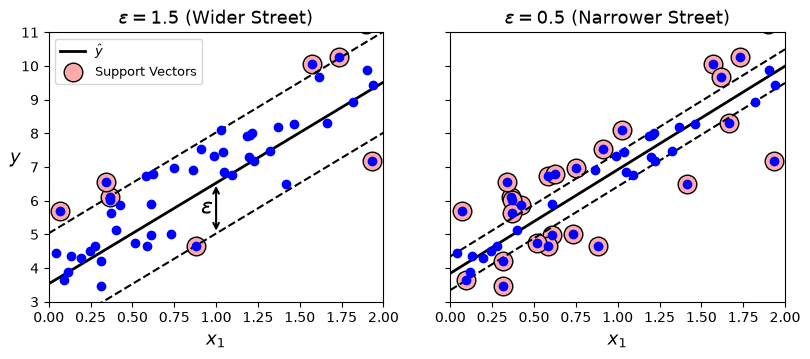

In [10]:
from sklearn.svm import LinearSVR

# 1. Generate synthetic linear data
np.random.seed(42)
m = 50
X = 2 * np.random.rand(m, 1)
y = (4 + 3 * X + np.random.randn(m, 1)).ravel()

# 2. Train two LinearSVR models with different margin widths (epsilon)
svm_reg1 = LinearSVR(epsilon=1.5, random_state=42, max_iter=10000)
svm_reg2 = LinearSVR(epsilon=0.5, random_state=42, max_iter=10000)
svm_reg1.fit(X, y)
svm_reg2.fit(X, y)

# 3. Identify support vectors (points sitting on or outside the margin)
def find_support_vectors(svm_reg, X, y):
    y_pred = svm_reg.predict(X)
    off_margin = (np.abs(y - y_pred) >= svm_reg.epsilon)
    return np.argwhere(off_margin)

svm_reg1.support_ = find_support_vectors(svm_reg1, X, y)
svm_reg2.support_ = find_support_vectors(svm_reg2, X, y)

# 4. Plot both models side-by-side
def plot_svm_regression(svm_reg, X, y, axes):
    x1s = np.linspace(axes[0], axes[1], 100).reshape(100, 1)
    y_pred = svm_reg.predict(x1s)
    plt.plot(x1s, y_pred, "k-", linewidth=2, label=r"$\hat{y}$")
    plt.plot(x1s, y_pred + svm_reg.epsilon, "k--")
    plt.plot(x1s, y_pred - svm_reg.epsilon, "k--")
    plt.scatter(X[svm_reg.support_], y[svm_reg.support_], s=180, facecolors='#FFAAAA', edgecolors='k', label="Support Vectors")
    plt.plot(X, y, "bo")
    plt.xlabel(r"$x_1$", fontsize=13)
    plt.axis(axes)

eps_x1 = 1.0
eps_y_pred = float(svm_reg1.predict([[eps_x1]])[0])

fig, axes = plt.subplots(ncols=2, figsize=(9.5, 3.5), sharey=True)
plt.sca(axes[0])
plot_svm_regression(svm_reg1, X, y, [0, 2, 3, 11])
plt.title(rf"$\epsilon = {svm_reg1.epsilon}$ (Wider Street)", fontsize=13)
plt.ylabel(r"$y$", fontsize=13, rotation=0)
plt.legend(loc="upper left", fontsize=9)
plt.annotate(
    '', xy=(eps_x1, eps_y_pred), xycoords='data',
    xytext=(eps_x1, eps_y_pred - svm_reg1.epsilon),
    textcoords='data', arrowprops={'arrowstyle': '<->', 'linewidth': 1.5}
)
plt.text(0.91, 5.6, r"$\epsilon$", fontsize=16, weight="bold")

plt.sca(axes[1])
plot_svm_regression(svm_reg2, X, y, [0, 2, 3, 11])
plt.title(rf"$\epsilon = {svm_reg2.epsilon}$ (Narrower Street)", fontsize=13)
save_fig("svm_regression_plot")
plt.show()


**What's going on in Figure 5-10:**
* **Solid Line ($\hat{y}$)**: The regression prediction line.
* **Dashed Lines (Gutters)**: The margin around the line, spaced at distance $\epsilon$ on each side (total width $= 2\epsilon$).
* **$\epsilon = 1.5$ (Left)**: A wide street accommodates almost all data points. Very few points fall outside the street (fewer support vectors).
* **$\epsilon = 0.5$ (Right)**: A narrower street forces more points outside the boundary, creating more support vectors to constrain the line.

## 10. Non-linear SVM Regression: Polynomial Kernel (Figure 5-11)

Just like classification, SVM Regression supports the **kernel trick** to fit non-linear relationships. Using `SVR(kernel="poly")`, the margin becomes a **curved tubular street** hugging the non-linear pattern.

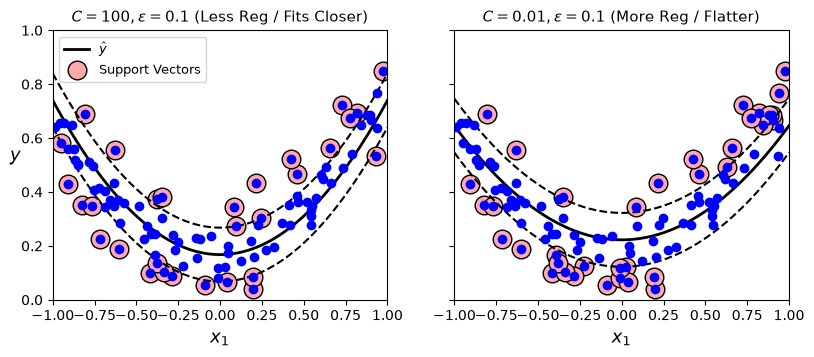

In [11]:
from sklearn.svm import SVR

# 1. Generate non-linear (quadratic) synthetic data
np.random.seed(42)
m = 100
X = 2 * np.random.rand(m, 1) - 1
y = (0.2 + 0.1 * X + 0.5 * X**2 + np.random.randn(m, 1)/10).ravel()

# 2. Train 2nd-degree polynomial SVR with high vs low C
svm_poly_reg1 = SVR(kernel="poly", degree=2, C=100, epsilon=0.1, gamma="scale")
svm_poly_reg2 = SVR(kernel="poly", degree=2, C=0.01, epsilon=0.1, gamma="scale")
svm_poly_reg1.fit(X, y)
svm_poly_reg2.fit(X, y)

# 3. Plot both side-by-side
fig, axes = plt.subplots(ncols=2, figsize=(9.5, 3.5), sharey=True)
plt.sca(axes[0])
plot_svm_regression(svm_poly_reg1, X, y, [-1, 1, 0, 1])
plt.title(rf"$C={svm_poly_reg1.C}, \epsilon={svm_poly_reg1.epsilon}$ (Less Reg / Fits Closer)", fontsize=11)
plt.ylabel(r"$y$", fontsize=13, rotation=0)
plt.legend(loc="upper left", fontsize=9)

plt.sca(axes[1])
plot_svm_regression(svm_poly_reg2, X, y, [-1, 1, 0, 1])
plt.title(rf"$C={svm_poly_reg2.C}, \epsilon={svm_poly_reg2.epsilon}$ (More Reg / Flatter)", fontsize=11)
save_fig("svm_with_polynomial_kernel_plot")
plt.show()


**What's going on in Figure 5-11:**
* **Curved Margin (Tube)**: The polynomial kernel bends the margin into a curved channel holding the data points.
* **$C = 100$ (Left)**: High $C$ = low regularization $\to$ model fits the training points closely, with very few points falling outside the tube.
* **$C = 0.01$ (Right)**: Low $C$ = high regularization $\to$ flattens the prediction line, tolerating more points outside the margin to prevent overfitting.